<a href="https://colab.research.google.com/github/cbvxil/international-airpassengers-project/blob/main/project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Capstone project - Air passengers, start to finish

The course pipeline, on this series: explore it, decompose it, set the
benchmark floor, check what the floor leaves on the table, fit a model
through the framework, cross-validate, and read the result against the
floor.

**What is graded is the process, not the number.** A low MASE from one
holdout with no intervals scores worse than an honest analysis that
concludes the benchmark wins.

Full rules and report requirements: `brief.md`. Grading: `rubric.md`. This
notebook is the first deliverable; it should run top to bottom in under ten
minutes on Colab.

This notebook is a starter. You may swap in your own series or your own
framework - see "Your own data or method" in `brief.md`.

In [46]:
import sys

if "google.colab" in sys.modules:
    !git clone -q https://github.com/SDAIAAcademy/international-airpassengers-project.git /content/proj
    %cd /content/proj
    !pip install -q -e .

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from coursekit import plotting as P
from coursekit import scoring

P.use_course_style()

SEASON_LENGTH = 12
H = 12            # forecast horizon for cross-validation
H_REPORT = 24     # forecast horizon for the report

fatal: destination path '/content/proj' already exists and is not an empty directory.
/content/proj
  Installing build dependencies ... done
  Checking if build backend supports build_editable ... done
  Getting requirements to build editable ... done
  Installing backend dependencies ... done
  Preparing editable metadata (pyproject.toml) ... done
  Building editable for international-airpassengers-project (pyproject.toml) ... done


---
# 0. The data

Monthly international air passenger numbers, 1949-01 to 1960-12: 144
observations, no gaps. The Box & Jenkins classic (1970) — twelve years of
growth, and a year that does not repeat the same way twice.

Fetched from statsmodels' R-datasets on first run; no download step.

In [47]:
from statsmodels.datasets import get_rdataset

raw = get_rdataset("AirPassengers").data
t = raw["time"].astype(float).to_numpy()
years = np.floor(t).astype(int)
months = np.clip(np.round((t - years) * 12).astype(int) + 1, 1, 12)
df = pd.DataFrame({
    "unique_id": "Air passengers (Box & Jenkins)",
    "ds": pd.to_datetime(pd.Series(years).astype(str) + "-" +
                         pd.Series(months).astype(str).str.zfill(2) + "-01"),
    "y": raw["value"].astype(float),
}).sort_values("ds").reset_index(drop=True)
df.head()

,unique_id,ds,y
0,Air passengers (Box & Jenkins),1949-01-01,112.0
1,Air passengers (Box & Jenkins),1949-02-01,118.0
2,Air passengers (Box & Jenkins),1949-03-01,132.0
3,Air passengers (Box & Jenkins),1949-04-01,129.0
4,Air passengers (Box & Jenkins),1949-05-01,121.0


In [ ]:
# TODO: confirm the calendar. How many months, what range, any gaps?
#       (Same three checks you ran on the spine on Day 1.)
n_obs =  len(df)
range_ = (df["ds"].min(), df["ds"].max())

expected_dates = pd.date_range(
    start=range_[0],
    end=range_[1],
    freq="MS"
)
n_gaps = len(expected_dates.difference(df["ds"]))
print(f"{n_obs} months, {range_[0].date()} to {range_[1].date()}, {n_gaps} gaps")

144 months, 1949-01-01 to 1960-12-01, 0 gaps


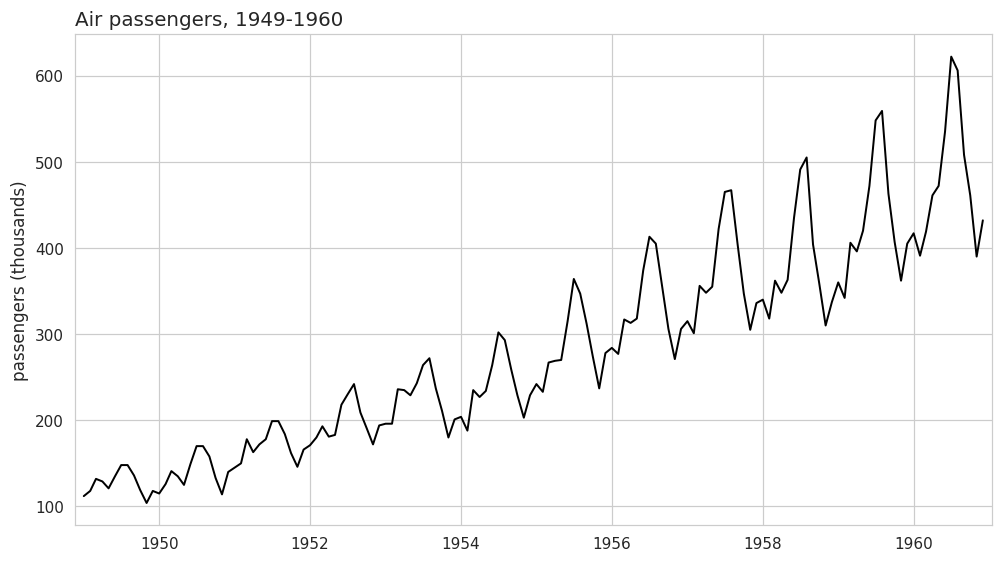

In [48]:
P.plot_series(df, title="Air passengers, 1949-1960",
              ylabel="passengers (thousands)", xlabel="")
plt.show()

**First read.** Before any model, write two sentences that describe this
series in plain language - the kind a non-forecaster could repeat. (Trend?
Seasonality? What happens to the swings as the level grows? Cycle?) These two
sentences belong at the top of your report.

---
# 1. Exploration and shape

The Day 1 toolkit, in order. Every chart should carry its claim: a title that
says what it shows, not just "series".

**1.1 Decompose.** STL, additive, period 12. Read all three panels: which
component does the work, and what does the remainder look like?

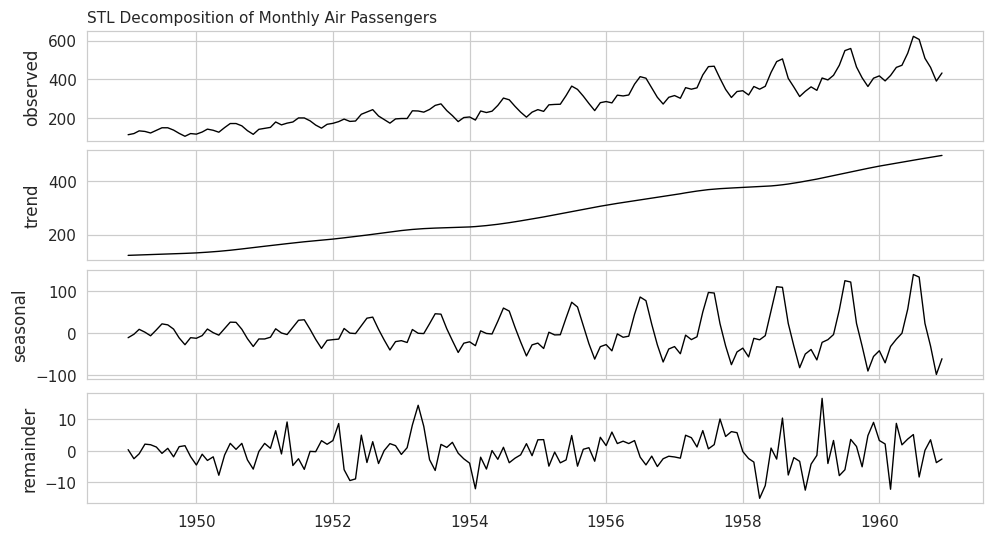

Trend range: 123 to 496
Seasonal amplitude: 50 (1949) to 237 (1960)
Residual SD: 3.3 (first 3 years) to 6.9 (last 3 years)


In [49]:
# TODO: STL decomposition (statsmodels), additive, period=12.

from statsmodels.tsa.seasonal import STL

# Explore the trend, seasonal pattern, and remaining variation.
series = df.set_index("ds")["y"]
stl_result = STL(series, period=SEASON_LENGTH).fit()

dcmp = pd.DataFrame({
    "ds": df["ds"].to_numpy(),
    "observed": df["y"].to_numpy(),
    "trend": stl_result.trend,
    "seasonal": stl_result.seasonal,
    "remainder": stl_result.resid,
})

P.decomposition_plot(
    dcmp,
    cols=["observed", "trend", "seasonal", "remainder"],
    title="STL Decomposition of Monthly Air Passengers",
    x="ds"
)
plt.show()

# Compare seasonal amplitude and residual variability over time.
annual_amplitude = (
    dcmp.groupby(dcmp["ds"].dt.year)["seasonal"]
    .agg(lambda values: values.max() - values.min())
)

early_residual_sd = dcmp["remainder"].iloc[:36].std()
late_residual_sd = dcmp["remainder"].iloc[-36:].std()

print(
    f"Trend range: {dcmp['trend'].min():.0f} "
    f"to {dcmp['trend'].max():.0f}"
)
print(
    f"Seasonal amplitude: {annual_amplitude.iloc[0]:.0f} "
    f"(1949) to {annual_amplitude.iloc[-1]:.0f} (1960)"
)
print(
    f"Residual SD: {early_residual_sd:.1f} "
    f"(first 3 years) to {late_residual_sd:.1f} "
    f"(last 3 years)"
)


**1.2 Trend and seasonal strength.** The two numbers from Day 1, computed
the same way (textbook formulas on the STL components). State what they
imply for model choice.

In [51]:
# TODO: trend_strength and seasonal_strength from the STL components.

remainder = dcmp["remainder"]
trend = dcmp["trend"]
seasonal = dcmp["seasonal"]

trend_strength = max(
    0, 1 - remainder.var() / (trend + remainder).var()
)

seasonal_strength = max(
    0, 1 - remainder.var() / (seasonal + remainder).var()
)

print(f"Strength of trend: {trend_strength:.2f}")
print(f"Strength of seasonality: {seasonal_strength:.2f}")


Strength of trend: 1.00
Strength of seasonality: 0.99


### **1.3 Autocorrelation.** The ACF of the raw series. What is at lag 12?

The ACF of the raw series shows a strong positive autocorrelation at lag 12. This means that passenger numbers are strongly related to the numbers 12 months earlier, indicating a yearly seasonal pattern. The high autocorrelation suggests that the series has strong seasonality.
At 24? What does that tell you before you fit anything?

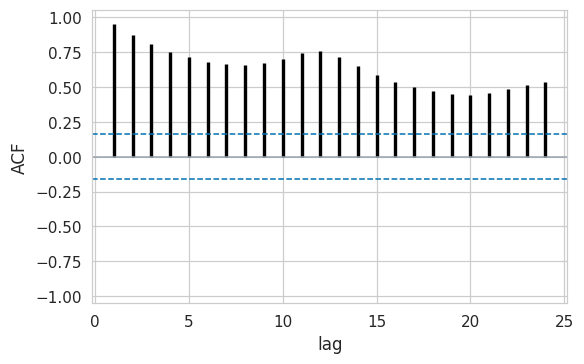

In [52]:
# TODO: ACF plot of df["y"] (P.acf_plot), 24 lags.
P.acf_plot(
    df["y"],
    nlags=24
)
plt.show()

---
# 2. The floor

The seasonal naive is the first model you fit on any series - not as a
formality, as the thing everything else has to beat. Fit it, check what it
leaves on the table, and give it an honest interval.

In [53]:
from statsforecast import StatsForecast
from statsforecast.models import SeasonalNaive

floor_sf = StatsForecast(models=[SeasonalNaive(season_length=SEASON_LENGTH)],
                         freq="MS", n_jobs=1)
floor_fc = floor_sf.forecast(df=df, h=H_REPORT, level=scoring.LEVELS)
floor_fc.head()

,unique_id,ds,SeasonalNaive,SeasonalNaive-lo-20,SeasonalNaive-lo-40,SeasonalNaive-lo-60,SeasonalNaive-lo-80,SeasonalNaive-lo-95,SeasonalNaive-hi-20,SeasonalNaive-hi-40,SeasonalNaive-hi-60,SeasonalNaive-hi-80,SeasonalNaive-hi-95
0,Air passengers (Box & Jenkins),1961-01-01,417.0,407.799511,397.956005,386.435898,370.4595,345.822448,426.200489,436.043995,447.564102,463.5405,488.177552
1,Air passengers (Box & Jenkins),1961-02-01,391.0,381.799511,371.956005,360.435898,344.4595,319.822448,400.200489,410.043995,421.564102,437.5405,462.177552
2,Air passengers (Box & Jenkins),1961-03-01,419.0,409.799511,399.956005,388.435898,372.4595,347.822448,428.200489,438.043995,449.564102,465.5405,490.177552
3,Air passengers (Box & Jenkins),1961-04-01,461.0,451.799511,441.956005,430.435898,414.4595,389.822448,470.200489,480.043995,491.564102,507.5405,532.177552
4,Air passengers (Box & Jenkins),1961-05-01,472.0,462.799511,452.956005,441.435898,425.4595,400.822448,481.200489,491.043995,502.564102,518.5405,543.177552


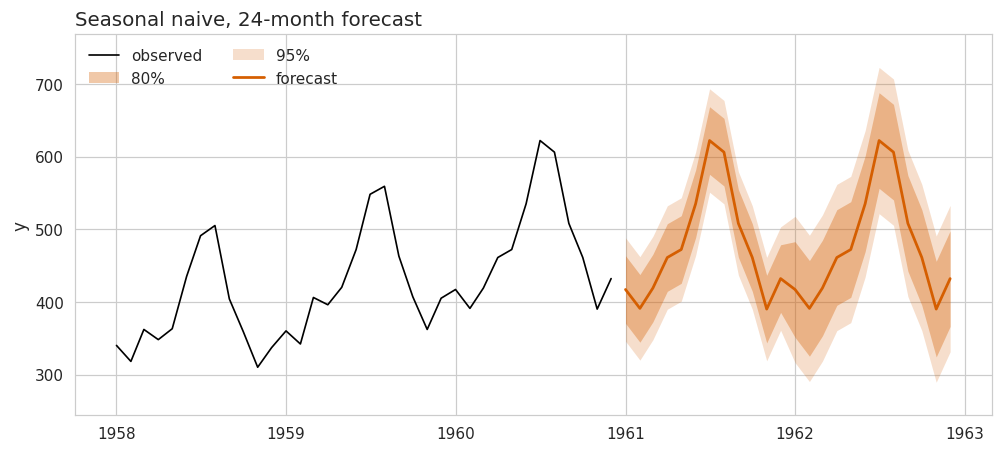

In [54]:
P.fan_chart(df, floor_fc.rename(columns={
            "SeasonalNaive": "mean",
            "SeasonalNaive-lo-20": "lo-20",
            "SeasonalNaive-lo-40": "lo-40",
            "SeasonalNaive-lo-60": "lo-60",
            "SeasonalNaive-lo-80": "lo-80",
            "SeasonalNaive-lo-95": "lo-95",
            "SeasonalNaive-hi-20": "hi-20",
            "SeasonalNaive-hi-40": "hi-40",
            "SeasonalNaive-hi-60": "hi-60",
            "SeasonalNaive-hi-80": "hi-80",
            "SeasonalNaive-hi-95": "hi-95",
            "ds": "ds"}),
            title="Seasonal naive, 24-month forecast",
            history_tail=36, levels=(80, 95))
plt.show()

**2.1 What is left on the table.** The floor's in-sample residuals are
``y_t - y_{t-12}`` over the series. Plot them, then their ACF (24 lags). Is
there a trend left? Correlation at the low lags? At 12? If it is not white
noise, what structure is it, and which kind of model eats that structure?

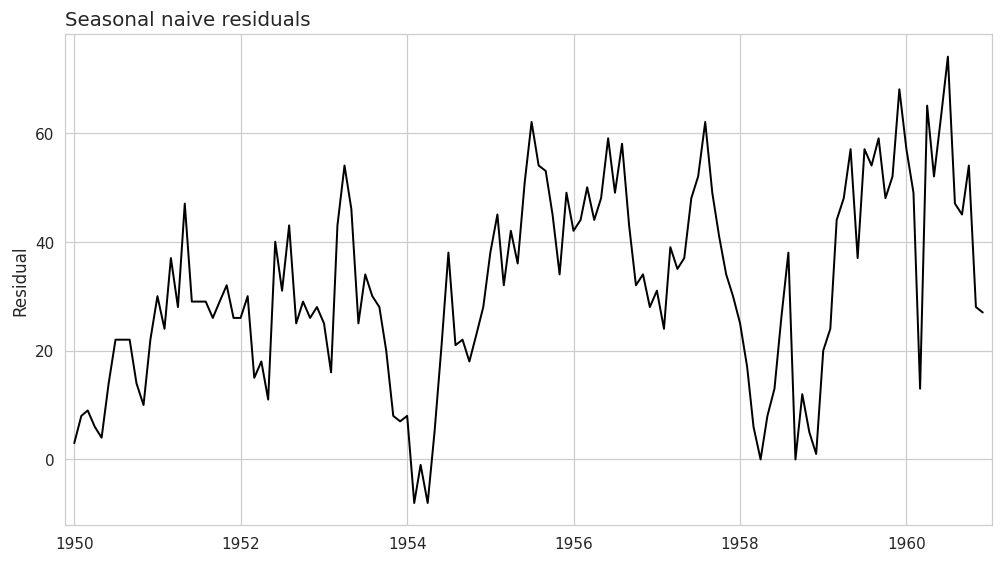

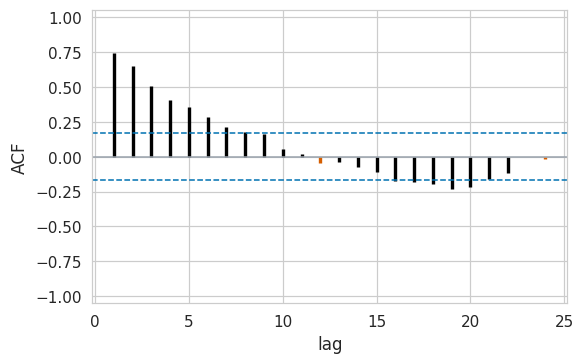

In [55]:
# TODO: the floor's residuals (y_t - y_{t-12}), a plot of them, and their
#       ACF with P.acf_plot (24 lags, highlight_every=SEASON_LENGTH).
resid_floor = (
    df["y"].to_numpy()[SEASON_LENGTH:]
    - df["y"].to_numpy()[:-SEASON_LENGTH]
)

P.plot_series(
    pd.DataFrame({
        "unique_id": "Seasonal naive residuals",
        "ds": df["ds"].iloc[SEASON_LENGTH:].to_numpy(),
        "y": resid_floor
    }),
    title="Seasonal naive residuals",
    ylabel="Residual",
    xlabel=""
)

plt.show()

P.acf_plot(
    pd.Series(resid_floor),
    nlags=24,
    highlight_every=SEASON_LENGTH
)

plt.show()

/tmp/ipykernel_19044/1685927995.py:21: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


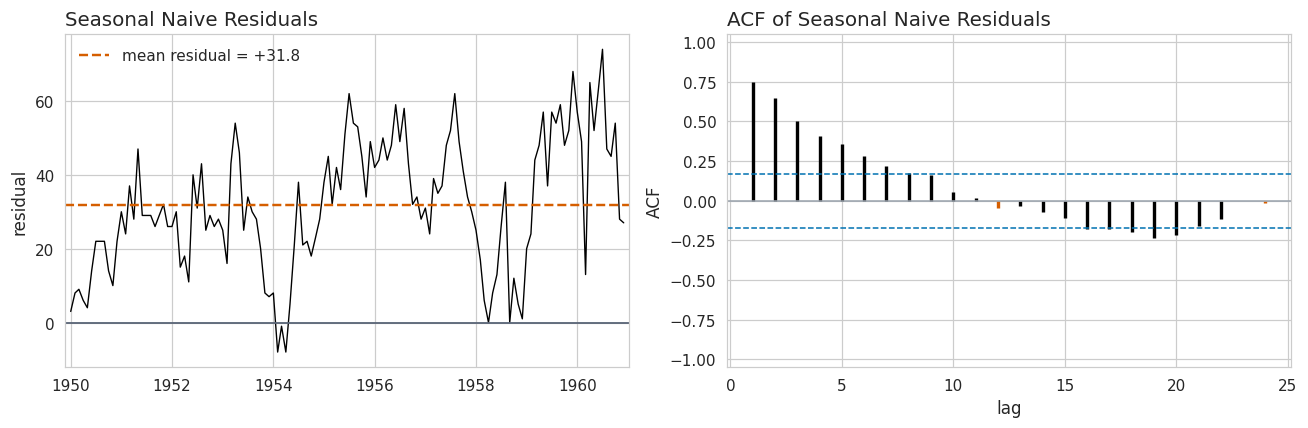

Mean residual: 31.77
ACF lag 1: 0.75
ACF lag 12: -0.04
Confidence bound: 0.17


In [56]:

resid_floor = df["y"] - df["y"].shift(SEASON_LENGTH)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

P.residual_time_plot(
    resid_floor,
    ds=df["ds"],
    ax=axes[0],
    show_mean=True,
    title="Seasonal Naive Residuals"
)

P.acf_plot(
    resid_floor.dropna(),
    nlags=24,
    ax=axes[1],
    highlight_every=SEASON_LENGTH,
    title="ACF of Seasonal Naive Residuals"
)

plt.tight_layout()
plt.show()

acf_values, bound = P.acf_values(
    resid_floor.dropna(),
    nlags=24
)

print("Mean residual:", round(resid_floor.mean(), 2))
print("ACF lag 1:", round(acf_values[0], 2))
print("ACF lag 12:", round(acf_values[11], 2))
print("Confidence bound:", round(bound, 2))


---
# 3. Your model: the framework

AutoGluon fits a zoo of models behind one call - every model in the zoo
below is a model you have met in this course. The install is large, so this
runs on Colab.

> Every cell in this section is **skip-guarded**: without `autogluon`
> installed it prints why and moves on, so the rest of the notebook still
> runs.

In [57]:
import importlib.util

HAS_AG = importlib.util.find_spec("autogluon") is not None
if not HAS_AG:
    print("autogluon is not installed. On Colab, run this and re-run the cell:")
    print("    !pip install -q 'autogluon.timeseries'")
    print("\n(Takes a few minutes. A runtime reset wipes it.)")
else:
    print("autogluon is available")

autogluon is available


**3.1 The data conversion stays visible.** AutoGluon has its own
frame, its own column names, its own fit loop and its own leaderboard.
Writing it out by hand once is the point - the gap between two APIs doing
the same job is the thing to notice.

| | this course | AutoGluon |
|---|---|---|
| id column | `unique_id` | `item_id` |
| time column | `ds` | `timestamp` |
| value column | `y` | `target` (nameable) |
| frame | `pd.DataFrame` | `TimeSeriesDataFrame` |

In [58]:
if HAS_AG:
    from autogluon.timeseries import TimeSeriesDataFrame, TimeSeriesPredictor

    # Long format to AutoGluon's long format: the same three columns, renamed.
    ag_long = df.rename(columns={"unique_id": "item_id", "ds": "timestamp"})
    tsdf = TimeSeriesDataFrame.from_data_frame(
        ag_long, id_column="item_id", timestamp_column="timestamp")

    # One 12-month holdout, cut the way AutoGluon expects.
    ag_train = tsdf.slice_by_timestep(None, -12)

    print(tsdf.head(3))
    print(f"\nfull: {len(tsdf)} rows   train: {len(ag_train)} rows")

                                               y
item_id                        timestamp        
Air passengers (Box & Jenkins) 1949-01-01  112.0
                               1949-02-01  118.0
                               1949-03-01  132.0

full: 144 rows   train: 132 rows


In [59]:
if HAS_AG:
    # Local models only - the same zoo this course taught, nothing neural.
    ZOO = {"Naive": {}, "SeasonalNaive": {}, "AutoETS": {},
           "AutoARIMA": {}, "Theta": {}}

    predictor = TimeSeriesPredictor(
        prediction_length=12, target="y", eval_metric="MASE",
        freq="MS", verbosity=1)
    predictor.fit(ag_train, hyperparameters=ZOO, time_limit=120)

In [60]:
# TODO: display the leaderboard on the held-out months (predictor.leaderboard(tsdf)).

if HAS_AG:
    # Compare the models on the available data
    results = predictor.leaderboard(tsdf)
    display(results[["model", "score_val", "score_test", "fit_order"]])

    # Get the number of validation windows
    trainer = getattr(predictor, "_learner", None)
    trainer = getattr(trainer, "trainer", None)
    windows = getattr(trainer, "num_val_windows", None)

    if isinstance(windows, (tuple, list)):
        windows = windows[0]

    if windows is None:
        windows = "1 (default)"

    print(f"Validation windows: {windows}")
    print(f"Window length: {predictor.prediction_length} months")
    print("Validation uses the end of the training data (1959)")

    # Check the validation scores
    print(f"\nScore range: {results.score_val.min():.3f} "
          f"to {results.score_val.max():.3f}")
    print("Scores are negative because AutoGluon uses -MASE.")
    print("A higher score is better.")

    # Show models ranked by validation score
    ranked_results = results.sort_values(
        "score_val", ascending=False
    )
    print("\nModels ranked by validation score:")
    print(ranked_results[["model", "score_val"]].to_string(index=False))

    print(f"\nBest model: {predictor.model_best}")


,model,score_val,score_test,fit_order
0,AutoARIMA,-1.575987,-0.608073,5
1,Theta,-1.633923,-0.875371,3
2,WeightedEnsemble,-1.535792,-0.929514,6
3,AutoETS,-1.554323,-1.169539,4
4,SeasonalNaive,-1.656513,-1.570881,2
5,Naive,-3.196371,-2.495895,1


Validation windows: 1
Window length: 12 months
Validation uses the end of the training data (1959)

Score range: -3.196 to -1.536
Scores are negative because AutoGluon uses -MASE.
A higher score is better.

Models ranked by validation score:
           model  score_val
WeightedEnsemble  -1.535792
         AutoETS  -1.554323
       AutoARIMA  -1.575987
           Theta  -1.633923
   SeasonalNaive  -1.656513
           Naive  -3.196371

Best model: WeightedEnsemble


**3.2 Read what it handed back.** What is the *sign* of `score_val`, and
what does the answer to "how many windows" mean for how much you should
trust this ranking? It decides what the next section does with this table.
And: does the shortlist agree with the shape you read in section 1?



*1. Sign of the scores**

All validation scores (`score_val`) are negative, ranging from -1.54 to -3.20. AutoGluon reports negative MASE values so that higher scores are better. Therefore, the score closest to zero represents the best model. A MASE of 1.54 indicates that the model performed worse than the seasonal-naive benchmark on that validation window.

**2. Models evaluated**

AutoGluon trained five forecasting models: Naive, SeasonalNaive, AutoETS, AutoARIMA, and Theta. It also created a WeightedEnsemble that combines predictions from multiple models.

**3. Number of evaluation windows**

The leaderboard uses one validation window containing the final 12 months of the training data (1959). The test score comes from another single 12-month window (1960). Since each score represents only one year, it may not reflect performance across different periods.

**4. Reliability of the ranking**

The leaderboard is useful for selecting candidate models, but it is less reliable for determining their final ranking. The models that capture both trend and seasonality generally perform better than the simple baseline models, supporting the findings from Section 1. However, the ensemble, AutoETS, and AutoARIMA have very similar validation scores, differing by only about 0.04 MASE. Their ranking changes on the 1960 test window, where AutoARIMA achieves 0.61, Theta 0.88, and AutoETS 1.17 MASE. This shows that the best model can change depending on the evaluation period.

**5. Models selected for further evaluation**

The three individual models carried forward are AutoARIMA, AutoETS, and Theta (called AutoTheta in StatsForecast). They all capture trend and seasonality and can be evaluated under the same cross-validation settings. The WeightedEnsemble has no direct StatsForecast equivalent, but an ensemble could be explored later if no individual model consistently performs best.

The leaderboard is used only to select candidate models. The final comparison will rely on the results from the multi-window evaluation harness.

---
# 4. The harness

The framework's ranking came from one internal split. One holdout is not a
ranking. So the shortlist goes through the rolling-origin harness: eight
origins, twelve months each, the whole distribution scored - and the floor
stays in the table.

In [61]:
sf_cv = StatsForecast(
    models=[SeasonalNaive(season_length=SEASON_LENGTH)],
    freq="MS", n_jobs=1)
cv = sf_cv.cross_validation(df=df, h=H, step_size=H, n_windows=8,
                            level=scoring.LEVELS)
cv.head()

,unique_id,ds,cutoff,y,SeasonalNaive,SeasonalNaive-lo-20,SeasonalNaive-lo-40,SeasonalNaive-lo-60,SeasonalNaive-lo-80,SeasonalNaive-lo-95,SeasonalNaive-hi-20,SeasonalNaive-hi-40,SeasonalNaive-hi-60,SeasonalNaive-hi-80,SeasonalNaive-hi-95
0,Air passengers (Box & Jenkins),1953-01-01,1952-12-01,196.0,171.0,164.48674,157.518271,149.362895,138.052796,120.6116,177.51326,184.481729,192.637105,203.947204,221.3884
1,Air passengers (Box & Jenkins),1953-02-01,1952-12-01,196.0,180.0,173.48674,166.518271,158.362895,147.052796,129.6116,186.51326,193.481729,201.637105,212.947204,230.3884
2,Air passengers (Box & Jenkins),1953-03-01,1952-12-01,236.0,193.0,186.48674,179.518271,171.362895,160.052796,142.6116,199.51326,206.481729,214.637105,225.947204,243.3884
3,Air passengers (Box & Jenkins),1953-04-01,1952-12-01,235.0,181.0,174.48674,167.518271,159.362895,148.052796,130.6116,187.51326,194.481729,202.637105,213.947204,231.3884
4,Air passengers (Box & Jenkins),1953-05-01,1952-12-01,229.0,183.0,176.48674,169.518271,161.362895,150.052796,132.6116,189.51326,196.481729,204.637105,215.947204,233.3884


In [63]:
N_WINDOWS = len(cv["cutoff"].unique())

In [65]:

print("CV columns:")
print(cv.columns.tolist())

print("\nCurrent mycv:")
print(mycv.columns.tolist() if "mycv" in globals() else "mycv not found")


CV columns:
['unique_id', 'ds', 'cutoff', 'y', 'SeasonalNaive', 'SeasonalNaive-lo-20', 'SeasonalNaive-lo-40', 'SeasonalNaive-lo-60', 'SeasonalNaive-lo-80', 'SeasonalNaive-lo-95', 'SeasonalNaive-hi-20', 'SeasonalNaive-hi-40', 'SeasonalNaive-hi-60', 'SeasonalNaive-hi-80', 'SeasonalNaive-hi-95']

Current mycv:
['unique_id', 'ds', 'cutoff', 'y', 'AutoARIMA', 'AutoARIMA-lo-95', 'AutoARIMA-lo-80', 'AutoARIMA-lo-60', 'AutoARIMA-lo-40', 'AutoARIMA-lo-20', 'AutoARIMA-hi-20', 'AutoARIMA-hi-40', 'AutoARIMA-hi-60', 'AutoARIMA-hi-80', 'AutoARIMA-hi-95']


In [66]:


from statsforecast.models import AutoARIMA, AutoETS, AutoTheta, Naive, RandomWalkWithDrift

# Define the additional models
models = [
    AutoARIMA(season_length=SEASON_LENGTH),
    AutoETS(season_length=SEASON_LENGTH),
    AutoTheta(season_length=SEASON_LENGTH),
    Naive(),
    RandomWalkWithDrift()
]

# Run cross-validation
sf = StatsForecast(
    models=models,
    freq="MS",
    n_jobs=1
)

extra_cv = sf.cross_validation(
    df=df,
    h=H,
    step_size=H,
    n_windows=len(cv["cutoff"].unique()),
    level=scoring.LEVELS
)

# Check that the folds match
assert (extra_cv["cutoff"].unique() == cv["cutoff"].unique()).all(), \
    "Cross-validation folds do not match"

# Combine all predictions
allcv = cv.merge(
    extra_cv.drop(columns="y"),
    on=["unique_id", "ds", "cutoff"]
)

# Calculate model metrics
model_names = [
    "SeasonalNaive", "Naive", "RWD",
    "AutoETS", "AutoTheta", "AutoARIMA"
]

rows = {}

for model in model_names:
    metrics = scoring.score_cv(allcv, model, df)

    metrics["coverage_95"] = scoring.coverage(allcv, model, 95)

    lower = allcv[f"{model}-lo-80"]
    upper = allcv[f"{model}-hi-80"]

    metrics["width_80_pct"] = float(
        ((upper - lower) / allcv[model]).mean()
    )
    metrics["mean_error"] = float(
        (allcv["y"] - allcv[model]).mean()
    )

    rows[model] = metrics

RESULTS = pd.DataFrame(rows).T[
    [
        "mase", "rmsse", "crps", "coverage_80",
        "coverage_95", "width_80_pct", "mean_error",
        "mase_min", "mase_max"
    ]
].rename_axis("model")

RESULTS.round(3)


,mase,rmsse,crps,coverage_80,coverage_95,width_80_pct,mean_error,mase_min,mase_max
model,,,,,,,,,
SeasonalNaive,1.313,1.246,0.062,0.510,0.927,0.269,34.896,0.412,1.959
Naive,2.119,2.452,0.110,0.688,0.854,0.504,55.510,1.422,3.196
RWD,1.813,2.156,0.095,0.760,0.896,0.499,43.190,1.187,2.766
AutoETS,0.952,1.003,0.050,0.490,0.708,0.151,20.168,0.565,1.554
AutoTheta,0.898,0.988,0.046,0.594,0.760,0.217,17.280,0.451,1.405
AutoARIMA,0.647,0.683,0.034,0.698,0.844,0.134,5.878,0.330,1.594


SeasonalNaive       AutoARIMA      
                       MASE cov80      MASE cov80
forecast year                                    
1953                   1.19  0.67      0.44  0.75
1954                   0.68  0.92      0.39  0.83
1955                   1.96  0.08      0.77  0.50
1956                   1.66  0.25      0.33  1.00
1957                   1.38  0.67      0.41  0.92
1958                   0.41  1.00      0.64  0.75
1959                   1.66  0.25      1.59  0.00
1960                   1.57  0.25      0.61  0.83

AutoARIMA has lower MASE than SeasonalNaive in 7 out of 8 years.


/tmp/ipykernel_19044/3811662671.py:123: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


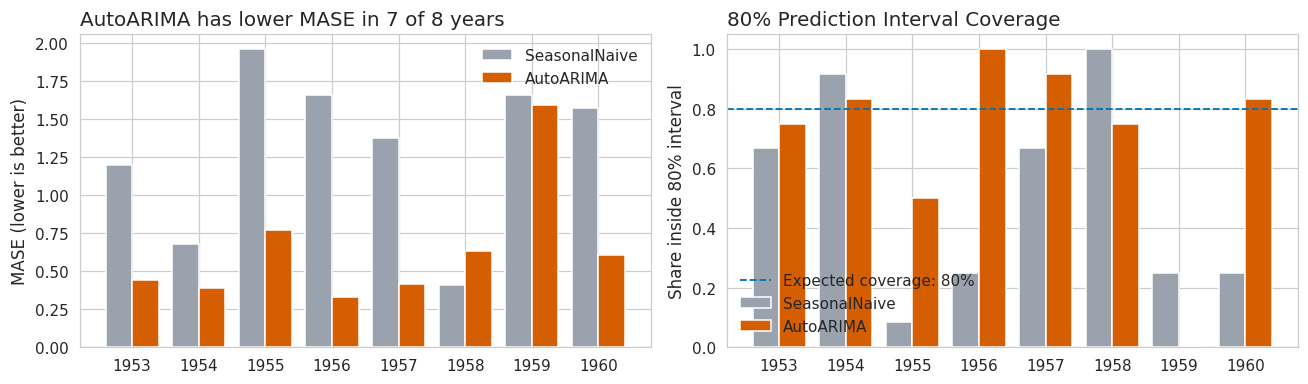

In [69]:

from utilsforecast.losses import mase as calculate_mase
import numpy as np
import matplotlib.pyplot as plt
import os

def evaluate_by_year(model_name):
    results = []

    for cutoff, group in allcv.groupby("cutoff"):
        history = df[df["ds"] <= cutoff]
        predictions = group.drop(columns="cutoff")

        mase_value = calculate_mase(
            predictions,
            models=[model_name],
            seasonality=SEASON_LENGTH,
            train_df=history
        )[model_name].iloc[0]

        coverage_value = scoring.coverage(group, model_name, 80)

        results.append({
            "forecast year": cutoff.year + 1,
            "MASE": float(mase_value),
            "cov80": coverage_value
        })

    return pd.DataFrame(results).set_index("forecast year")


# Compare SeasonalNaive with AutoARIMA
YEARLY_RESULTS = pd.concat(
    {
        "SeasonalNaive": evaluate_by_year("SeasonalNaive"),
        "AutoARIMA": evaluate_by_year("AutoARIMA")
    },
    axis=1
)

display(YEARLY_RESULTS.round(2))

# Count the years when AutoARIMA has lower MASE
better_years = (
    YEARLY_RESULTS[("AutoARIMA", "MASE")]
    < YEARLY_RESULTS[("SeasonalNaive", "MASE")]
).sum()

total_years = len(YEARLY_RESULTS)

print(
    f"AutoARIMA has lower MASE than SeasonalNaive "
    f"in {better_years} out of {total_years} years."
)

# Plot the results
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))

years = YEARLY_RESULTS.index.astype(str)
x = np.arange(len(years))
bar_width = 0.4

# Chart 1: MASE
axes[0].bar(
    x - bar_width / 2,
    YEARLY_RESULTS[("SeasonalNaive", "MASE")],
    bar_width,
    color=P.GREY,
    label="SeasonalNaive"
)

axes[0].bar(
    x + bar_width / 2,
    YEARLY_RESULTS[("AutoARIMA", "MASE")],
    bar_width,
    color=P.ORANGE,
    label="AutoARIMA"
)

axes[0].set(
    xticks=x,
    xticklabels=years,
    ylabel="MASE (lower is better)",
    title=f"AutoARIMA has lower MASE in {better_years} of {total_years} years"
)

axes[0].legend(frameon=False)

# Chart 2: 80% prediction interval coverage
axes[1].bar(
    x - bar_width / 2,
    YEARLY_RESULTS[("SeasonalNaive", "cov80")],
    bar_width,
    color=P.GREY,
    label="SeasonalNaive"
)

axes[1].bar(
    x + bar_width / 2,
    YEARLY_RESULTS[("AutoARIMA", "cov80")],
    bar_width,
    color=P.ORANGE,
    label="AutoARIMA"
)

axes[1].axhline(
    0.8,
    color=P.BLUE,
    linestyle="--",
    linewidth=1.2,
    label="Expected coverage: 80%"
)

axes[1].set(
    xticks=x,
    xticklabels=years,
    ylim=(0, 1.05),
    ylabel="Share inside 80% interval",
    title="80% Prediction Interval Coverage"
)

axes[1].legend(frameon=False, loc="lower left")

plt.tight_layout()

os.makedirs("figures", exist_ok=True)
plt.savefig("figures/02_harness.png", bbox_inches="tight")

plt.show()



/tmp/ipykernel_19044/1111894802.py:38: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


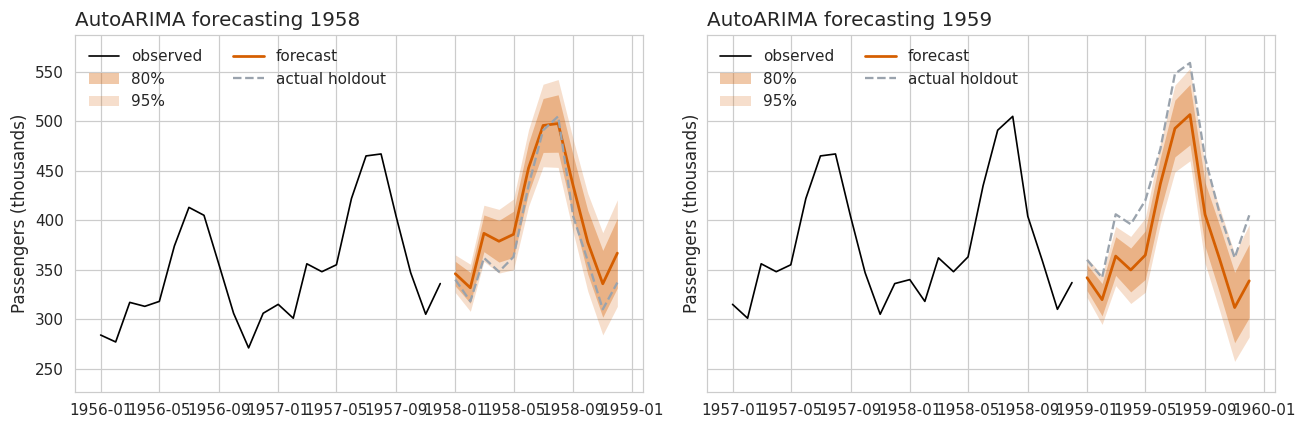

In [73]:


# Select forecasts for 1958 and 1959
fans = []

for year in [1958, 1959]:
    forecast = allcv[allcv["ds"].dt.year == year].copy()

    # Rename forecast columns
    forecast = forecast.rename(columns={
        "AutoARIMA": "mean",
        "AutoARIMA-lo-80": "lo-80",
        "AutoARIMA-hi-80": "hi-80",
        "AutoARIMA-lo-95": "lo-95",
        "AutoARIMA-hi-95": "hi-95"
    })

    fans.append(forecast)

# Create the charts
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)

for i, year in enumerate([1958, 1959]):
    forecast = fans[i]

    history = df[df["ds"] < forecast["ds"].min()]

    P.fan_chart(
        history,
        forecast,
        ax=axes[i],
        history_tail=24,
        levels=(80, 95),
        actual=forecast[["ds", "y"]],
        title=f"AutoARIMA forecasting {year}"
    )

    axes[i].set_ylabel("Passengers (thousands)")

plt.tight_layout()
plt.show()


**4.1 Read the table.** Does the harness confirm the leaderboard's
shortlist, or does it move it? For each model: where does it beat the
floor, where does it lose, and on which of the three metrics? A model that
wins the point forecast and loses the distribution is a real result -
report both halves. And what does each model's 80% coverage say about its
band?

The harness moves the leaderboard. AutoETS ranked first in the internal leaderboard, but the eight-year evaluation puts AutoARIMA first, followed by AutoTheta and AutoETS.

AutoARIMA: It beats the floor on all three metrics: MASE (0.65 vs. 1.31), scaled CRPS (0.034 vs. 0.062), and 80% coverage (70% vs. 51%). However, it loses to the floor in 1958, when repeating the previous year's values was more accurate. Its 80% coverage is better than the floor's, but it is still below the expected 80%.

AutoTheta: It beats the floor on point forecasting (MASE 0.90 vs. 1.31) and distribution forecasting (scaled CRPS 0.046 vs. 0.062). However, its 80% coverage is only 59%, meaning its prediction intervals are too narrow and miss many actual observations.

AutoETS: It also beats the floor on MASE (0.95 vs. 1.31) and scaled CRPS (0.050 vs. 0.062), but its 80% coverage is only 49%. Its selected model has no trend, which contributes to under-forecasting the growing passenger numbers. Therefore, better point forecasts do not necessarily mean reliable prediction intervals.

Coverage conclusion: None of the models achieves the expected 80% coverage. AutoARIMA performs best at 70%, followed by AutoTheta at 59% and AutoETS at 49%. This suggests that their 80% prediction intervals are generally too narrow. AutoARIMA performs better overall, but its performance deteriorates after sudden changes in the data, especially in 1959.

The drift and naive models can achieve higher coverage with wider prediction intervals, but wider intervals alone do not guarantee better probabilistic forecasts. The scaled CRPS helps evaluate the quality of the entire predictive distribution.

---
# 5. The report

The notebook is evidence; the report is the claim. Two to three pages, for a
manager who will not open the notebook:

- **The recommendation.** Which model you would ship, in one sentence, and
  the one number that earns it.
- **The intervals.** How wide, what they covered, and whether the band is
  honest. Coverage is the check a band cannot do alone.
- **The residuals.** What the floor - and your model - missed. A residual
  ACF is a fact; a sentence about what it means is the deliverable.
- **One change.** A specific next step - data, driver, frequency, horizon -
  and what you expect it to do.

Rules: every number in the report comes out of this notebook; no number
that could not have come out of the harness counts; no leakage - a fold's
fit and its denominator use only data that fold was allowed to see.

**Optional, for extra credit.** The series is a total across origins, so a
driver is a modelling choice, not a lookup: pick a region and pull its
monthly mean temperature from a public weather archive (for example
Open-Meteo's historical API - free, no key), cache it next to the CSV, and
regress on it. That is dynamic regression - and the cross-validation
discipline still applies to the regression's residuals.